# Getting started with cost minimization in `optimex`

This notebook demonstrates a compact end-to-end workflow for cost-minimizing time-explicit Life Cycle Optimization (LCO) in `optimex`. One synthetic product can be supplied by two alternative foreground processes. Both require an installation-related background purchase and a route-specific operating input. Time-dependent market prices are assigned to these directly purchased background products.

Using the same product system, the notebook determines:

1. the cost minimum without an environmental constraint,
2. the climate-impact minimum as a reference, and
3. the cost minimum subject to a cumulative climate budget, and
4. the Pareto frontier between cost and climate impact.

Together, these scenarios show how prices, discounting, and a cumulative climate budget affect installation and operation decisions. All quantities, prices, lifetimes, and environmental impacts are synthetic assumptions for demonstration purposes. The example demonstrates the software workflow.

## 1. Setup

Use a notebook kernel with this repository's `optimex`, Brightway,
`bw_temporalis`, Matplotlib, and the GLPK solver installed; see the
[installation guide](../docs/content/installation.md).
No ecoinvent data are needed.

The following cells write synthetic data to the dedicated Brightway project
`optimex_basic_example_econ_simple`. Rerunning replaces only this example's named
databases and method; do not store other work in that project.

In [1]:
from datetime import datetime
import sys
import warnings

warnings.filterwarnings("ignore", message="No fast sparse solver found")
warnings.filterwarnings("ignore", message=r"\s*It seems like you have an ARM architecture")
warnings.filterwarnings(
    "ignore", message=r"urllib3 .* doesn't match a supported version!"
)

import bw2data as bd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from bw_temporalis import TemporalDistribution
from IPython.display import display
from loguru import logger

from optimex import converter, lca_processor, optimizer, postprocessing
from optimex.economics import set_market_prices

# Keep the tutorial output focused on the inputs and results below.
logger.remove()
logger.add(sys.stderr, level="WARNING")

bd.projects.set_current("optimex_basic_example_econ_simple")

## 2. Product system and assumptions

![Two alternative foreground processes supply one product. Dashed arrows denote direct background purchases.](data/basic_example_econ/system.svg)

Rectangles are **processes**; the oval is a **product**. Dashed arrows denote
fixed background supplies, not additional technology choices. Both processes
also emit CO2 directly. Construction and operating supplies carry upstream CO2.

The conventional process needs less construction input; the advanced process
needs twice as much, but emits less during operation. Their route-specific
operating inputs are named `conventional_input` and `advanced_input`.

- Demand: 10 product units each year, 2025-2034; no initial capacity.
- One installed process unit can supply 1 product unit per year for five years,
  including its installation year. Capacity is continuous and can be idle.
- Costs: illustrative **real EUR with a 2025 price basis**, discounted at 3% to
  2025. No inflation, revenues, CO2 price, end-of-life costs, or residual value.
- Climate: kg CO2-eq, including foreground and background emissions, with a
  static factor of 1 kg CO2-eq/kg CO2. Impacts are not discounted.

Only the price of the advanced operating input changes. Technical coefficients
and background emission factors stay constant, isolating the price effect. The
falling price is an external assumption.

In [2]:
years = np.arange(2025, 2035)
lifetime = 5
annual_demand = 10.0
discount_rate = 0.03
background_databases = {2025: "background_2025", 2034: "background_2034"}

background_parameters = pd.DataFrame([
    {"input": "construction", "role": "installation, both routes",
     "kg CO2/unit": 1.0,
     "price in 2025 [EUR_2025/unit]": 4.0,
     "price in 2034 [EUR_2025/unit]": 4.0},
    {"input": "conventional_input", "role": "operation, conventional",
     "kg CO2/unit": 2.0,
     "price in 2025 [EUR_2025/unit]": 5.0,
     "price in 2034 [EUR_2025/unit]": 5.0},
    {"input": "advanced_input", "role": "operation, advanced",
     "kg CO2/unit": 1.0,
     "price in 2025 [EUR_2025/unit]": 6.0,
     "price in 2034 [EUR_2025/unit]": 3.0},
]).set_index("input")
background_parameters

,role,kg CO2/unit,price in 2025 [EUR_2025/unit],price in 2034 [EUR_2025/unit]
input,,,,
construction,"installation, both routes",1.0,4.0,4.0
conventional_input,"operation, conventional",2.0,5.0,5.0
advanced_input,"operation, advanced",1.0,6.0,3.0


## 3. Brightway data and market prices

The two background snapshots have identical inventories but different prices.
`optimex` interpolates the snapshot prices for the intervening calendar years.
All prices are expressed in real EUR with a 2025 price basis. Prices are attached
to **directly purchased background nodes**, not to foreground processes or
recursively to upstream exchanges. Foreground exchange amounts determine the
quantities purchased.

In [3]:
%%capture
biosphere = bd.Database("biosphere3")
biosphere.write({
    ("biosphere3", "CO2"): {
        "name": "carbon dioxide", "unit": "kg",
        "type": bd.labels.biosphere_node_default,
    },
})
method = ("illustrative", "climate_change")
bd.Method(method).register(unit="kg CO2-eq")
bd.Method(method).write([(("biosphere3", "CO2"), 1.0)])

for year, db_name in background_databases.items():
    data = {}
    for name, row in background_parameters.iterrows():
        data[(db_name, name)] = {
            "name": name, "reference product": name,
            "location": "GLO", "unit": "unit",
            "type": bd.labels.chimaera_node_default,
            "exchanges": [
                {"input": (db_name, name), "amount": 1.0,
                 "type": bd.labels.production_edge_default},
                {"input": ("biosphere3", "CO2"), "amount": row["kg CO2/unit"],
                 "type": bd.labels.biosphere_edge_default},
            ],
        }
    db = bd.Database(db_name)
    db.write(data)
    db.metadata["representative_time"] = datetime(year, 1, 1).isoformat()
    db.register()

In [4]:
price_data = pd.DataFrame([
    {"name": name, "location": "GLO", "year": year,
     "price": row[f"price in {year} [EUR_2025/unit]"]}
    for name, row in background_parameters.iterrows()
    for year in background_databases
])
set_market_prices(price_data, background_databases)

## 4. Installation, operation, and demand

Relative `TemporalDistribution` dates describe years since installation.
`operation=False` links construction to installed units, even if they are idle.
`operation=True` links production, operating purchases, and direct emissions to
the units actually running in each year.

The operation distribution has five weights of 1/5. **Exchange amounts below
are full-lifetime quantities**: production of 5 units becomes 1 unit/year;
5 units of operating input become 1 unit/year. Conventional direct CO2 is
4 kg/year, advanced direct CO2 is 1 kg/year, per running process unit.

In [5]:
installation_td = TemporalDistribution(
    date=np.array([0], dtype="timedelta64[Y]"),
    amount=np.array([1.0]),
)
operation_td = TemporalDistribution(
    date=np.arange(lifetime).astype("timedelta64[Y]"),
    amount=np.full(lifetime, 1.0 / lifetime),
)

foreground_data = {
    ("foreground", "product"): {
        "name": "Product", "unit": "unit",
        "type": bd.labels.product_node_default,
    },
}

In [6]:
foreground_data[("foreground", "conventional")] = {
    "name": "Conventional", "location": "GLO",
    "type": bd.labels.process_node_default,
    "operation_time_limits": (0, lifetime - 1),
    "exchanges": [
        {"input": ("foreground", "product"), "amount": float(lifetime),
         "type": bd.labels.production_edge_default,
         "temporal_distribution": operation_td, "operation": True},
        {"input": ("background_2025", "construction"), "amount": 1.0,
         "type": bd.labels.consumption_edge_default,
         "temporal_distribution": installation_td, "operation": False},
        {"input": ("background_2025", "conventional_input"), "amount": float(lifetime),
         "type": bd.labels.consumption_edge_default,
         "temporal_distribution": operation_td, "operation": True},
        {"input": ("biosphere3", "CO2"), "amount": 4.0 * lifetime,
         "type": bd.labels.biosphere_edge_default,
         "temporal_distribution": operation_td, "operation": True},
    ],
}

In [7]:
%%capture
foreground_data[("foreground", "advanced")] = {
    "name": "Advanced", "location": "GLO",
    "type": bd.labels.process_node_default,
    "operation_time_limits": (0, lifetime - 1),
    "exchanges": [
        {"input": ("foreground", "product"), "amount": float(lifetime),
         "type": bd.labels.production_edge_default,
         "temporal_distribution": operation_td, "operation": True},
        {"input": ("background_2025", "construction"), "amount": 2.0,
         "type": bd.labels.consumption_edge_default,
         "temporal_distribution": installation_td, "operation": False},
        {"input": ("background_2025", "advanced_input"), "amount": float(lifetime),
         "type": bd.labels.consumption_edge_default,
         "temporal_distribution": operation_td, "operation": True},
        {"input": ("biosphere3", "CO2"), "amount": 1.0 * lifetime,
         "type": bd.labels.biosphere_edge_default,
         "temporal_distribution": operation_td, "operation": True},
    ],
}
bd.Database("foreground").write(foreground_data)

In [8]:
demand_td = TemporalDistribution(
    date=np.array([f"{year}-01-01" for year in years], dtype="datetime64[s]"),
    amount=np.full(len(years), annual_demand),
)
functional_demand = {bd.get_node(database="foreground", code="product"): demand_td}

## 5. Prepare optimization inputs

`LCADataProcessor` reads the Brightway system and constructs the time-explicit
inventory and impact data. Setting `price_attribute` makes it also read the
market prices written above and interpolate them to every year. `ModelInputManager` transfers these data, including
the interpolated annual prices, and adds the discount rate and its reference
year. Demand dates define the modeled years, 2025-2034. This finite-horizon
example does not account for operation after 2034 or remaining asset value, so
late investments must be interpreted with that boundary in mind.

In [9]:
%%capture
config = lca_processor.LCAConfig(
    demand=functional_demand,
    temporal={
        "start_date": datetime(2025, 1, 1),
        "temporal_resolution": "year",
        "database_dates": {
            name: datetime(year, 1, 1) for year, name in background_databases.items()
        },
    },
    characterization_methods=[{
        "category_name": "climate_change", "brightway_method": method,
    }],
    # Two tiny background databases: no need for parallel worker processes.
    background_inventory={"calculation_method": "sequential"},
    price_attribute="market_price",
)
processor = lca_processor.LCADataProcessor(config)
manager = converter.ModelInputManager()
manager.parse_from_lca_processor(processor)
inputs = manager.override(
    discount_rate=discount_rate, discount_reference_year=int(years[0]),
)

In [10]:
# Inspect how the snapshot prices were interpolated to every year.
processed_prices = pd.DataFrame({
    flow: [inputs.intermediate_flow_prices[flow, int(year)] for year in years]
    for flow in ("construction", "conventional_input", "advanced_input")
}, index=years)
processed_prices.index.name = "Year"
processed_prices.columns.name = "Price [EUR_2025/unit]"
processed_prices

Price [EUR_2025/unit],construction,conventional_input,advanced_input
Year,,,
2025,4.0,5.0,6.000000
2026,4.0,5.0,5.666667
2027,4.0,5.0,5.333333
2028,4.0,5.0,5.000000
2029,4.0,5.0,4.666667
2030,4.0,5.0,4.333333
2031,4.0,5.0,4.000000
2032,4.0,5.0,3.666667
2033,4.0,5.0,3.333333


## 6. Cost minimum and climate reference

The first model minimizes discounted background-purchase costs
(`objective="cost"`). A second model uses the environmental objective to
establish the minimum climate impact attainable with the same demand,
inventories, and technologies.

In [11]:
%%capture
cost_model = optimizer.create_model(inputs, name="cost_minimum", objective="cost")
cost_model, minimum_cost, _ = optimizer.solve_model(
    cost_model, solver_name="glpk", tee=False,
)

In [12]:
%%capture
climate_model = optimizer.create_model(
    inputs, name="climate_reference", objective_category="climate_change",
)
climate_model, minimum_climate, _ = optimizer.solve_model(
    climate_model, solver_name="glpk", tee=False,
)

## 7. Cost minimum with a cumulative climate budget

The illustrative budget is **330 kg CO2-eq over all ten years**, not an annual
limit or a carbon price. It lies between the climate impacts of the two reference
solutions and therefore creates a trade-off between the two objectives. The
value is a synthetic assumption, not a policy target derived from external
evidence.

Only one input changes: `cumulative_category_impact_limits`.

In [13]:
%%capture
def climate_total(model):
    impacts = postprocessing.PostProcessor(model).get_impacts()
    return impacts["climate_change"].to_numpy().sum()


climate_budget = 330.0
assert minimum_climate < climate_budget < climate_total(cost_model)
constrained_inputs = manager.override(
    cumulative_category_impact_limits={"climate_change": climate_budget},
)
constrained_model = optimizer.create_model(
    constrained_inputs, name="cost_with_climate_budget", objective="cost",
)
constrained_model, constrained_cost, _ = optimizer.solve_model(
    constrained_model, solver_name="glpk", tee=False,
)

## 8. Results

The table compares total discounted cost and cumulative climate impact. The
climate reference minimizes climate impact, yet its costs are reported too:
every model with prices computes the costs of its pathway, whatever it
minimizes.
`PostProcessor.get_costs()` splits the costs into installation-driven and
operation-driven purchases, which sum to the reported total. They follow the
corresponding background purchases and should not be interpreted as complete
CAPEX and OPEX accounts; for example, fixed operating costs are omitted.

In [14]:
models = {
    "Cost minimum": cost_model,
    "Climate reference": climate_model,
    "Cost + climate budget": constrained_model,
}
rows = []
for scenario, model in models.items():
    costs = postprocessing.PostProcessor(model).get_costs(discounted=True)
    rows.append({
        "Scenario": scenario,
        "Total cost [EUR_2025 PV]": costs.to_numpy().sum(),
        "Climate [kg CO2-eq]": climate_total(model),
        "Installation-driven cost [EUR_2025 PV]": costs["installation"].to_numpy().sum(),
        "Operation-driven cost [EUR_2025 PV]": costs["operation"].to_numpy().sum(),
    })
comparison = pd.DataFrame(rows).set_index("Scenario")
comparison.round(2)

,Total cost [EUR_2025 PV],Climate [kg CO2-eq],Installation-driven cost [EUR_2025 PV],Operation-driven cost [EUR_2025 PV]
Scenario,,,,
Cost minimum,494.86,430.0,109.01,385.85
Climate reference,551.52,240.0,149.01,402.51
Cost + climate budget,524.68,330.0,130.06,394.62


### Installation and production

Use the existing `PostProcessor` to extract results. The table shows **newly
installed process units**, not annual production. The plots show product
supplied in each year; since output is 1 unit per running process unit and year,
they also reveal which technology operates. A mix is allowed; these are not
integer, all-or-nothing plant choices.

In [15]:
postprocessors = {
    name: postprocessing.PostProcessor(model) for name, model in models.items()
}
routes = ["conventional", "advanced"]
production = {
    name: pp.get_production().xs("product", axis=1, level="Product")[routes]
    for name, pp in postprocessors.items()
}
installations = pd.concat({
    name: pp.get_installation()[routes] for name, pp in postprocessors.items()
}, names=["Scenario", "Installation year"])
installations.loc[installations.abs().sum(axis=1) > 1e-7].round(2)

Process                                  conventional  advanced
Scenario              Installation year                        
Cost minimum          2025                      10.00      0.00
                      2030                       0.00     10.00
Climate reference     2025                       0.00     10.00
                      2030                       0.00     10.00
Cost + climate budget 2025                       4.74      5.26
                      2030                       0.00     10.00

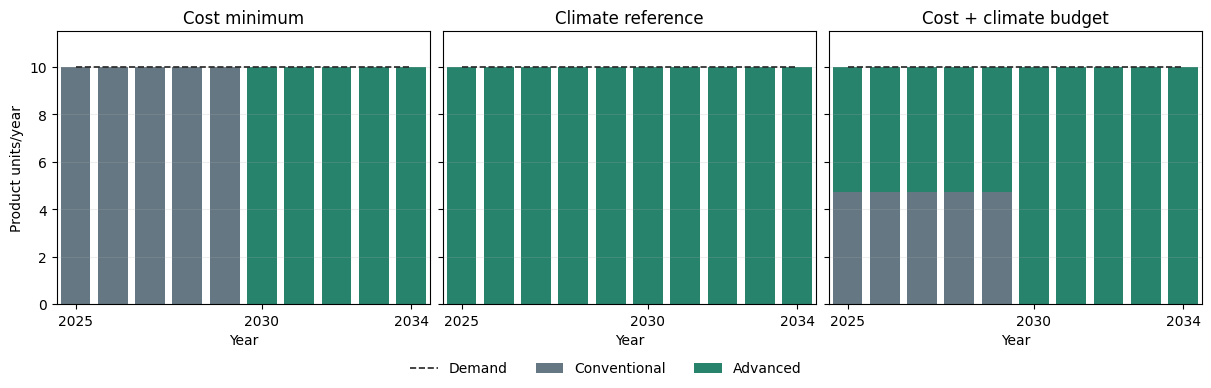

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True, layout="constrained")
for ax, (name, data) in zip(axes, production.items()):
    ax.bar(data.index, data["conventional"], color="#657783", label="Conventional")
    ax.bar(data.index, data["advanced"], bottom=data["conventional"],
           color="#27836c", label="Advanced")
    ax.plot(years, demand_td.amount, color="#242424", linestyle="--",
            linewidth=1.2, label="Demand")
    ax.set(title=name, xlabel="Year", xlim=(years[0] - 0.5, years[-1] + 0.5),
           ylim=(0, annual_demand * 1.15), xticks=[2025, 2030, 2034])
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Product units/year")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
plt.show()

### Sanity checks and interpretation

The following checks confirm the annual-unit convention, price assignment,
demand fulfillment, cost identity, and cumulative climate budget for this
example. They do not constitute a test of every `optimex` feature. A
climate-minimizing solution is not necessarily the cheapest among multiple
solutions with the same minimum climate impact.

In [17]:
for route in ("conventional", "advanced"):
    assert all(
        np.isclose(inputs.foreground_production[route, "product", tau], 1.0)
        for tau in range(lifetime)
    )
np.testing.assert_allclose(
    [inputs.intermediate_flow_prices["advanced_input", int(year)] for year in years],
    np.linspace(6.0, 3.0, len(years)),
)
for data in production.values():
    np.testing.assert_allclose(data.sum(axis=1), demand_td.amount, atol=1e-6)
np.testing.assert_allclose(
    comparison["Total cost [EUR_2025 PV]"],
    comparison["Installation-driven cost [EUR_2025 PV]"]
    + comparison["Operation-driven cost [EUR_2025 PV]"],
    atol=1e-6,
)
assert minimum_cost <= constrained_cost + 1e-6
assert minimum_climate - 1e-6 <= climate_total(constrained_model) <= climate_budget + 1e-6
np.testing.assert_allclose(comparison.loc["Cost minimum", "Total cost [EUR_2025 PV]"], minimum_cost)
assert constrained_cost <= comparison.loc["Climate reference", "Total cost [EUR_2025 PV]"] + 1e-6

print(f"Cumulative climate impact: {climate_total(constrained_model):.2f} / "
      f"{climate_budget:.2f} kg CO2-eq")
print(f"Additional discounted cost versus cost minimum: "
      f"{constrained_cost - minimum_cost:.2f} EUR_2025")

Cumulative climate impact: 330.00 / 330.00 kg CO2-eq
Additional discounted cost versus cost minimum: 29.82 EUR_2025


The cost minimum initially uses the conventional process and switches to the
advanced process when capacity is replaced in 2030. Although the two operating
input prices are equal in 2028, the installation-related cost difference and
the five-year lifetimes affect the investment decision. The climate reference
uses the lower-emission advanced process, while the cumulative climate budget
brings part of this capacity forward relative to the unconstrained cost minimum.

These results illustrate the interaction of installation timing, operation,
prices, discounting, and a cumulative climate budget.


## 9. Pareto frontier between cost and climate impact

Section 7 solved the cost minimum for one climate budget. Repeating this for a
range of budgets, from the minimum climate impact up to the impact of the cost
minimum, traces the **Pareto frontier**: for each budget, the lowest discounted
cost that respects it. This is the epsilon-constraint method; each point is a
separate model built from the same inputs, with only the budget changed.

`optimizer.solve_series` solves all points in one call and returns one table,
indexed by budget. Each point is made with `inputs.model_copy(update=...)`, which
shares everything except the budget with `inputs`. With HiGHS or Gurobi,
`solve_series` then builds the model once and only updates the budget for every
point, which is much faster for large systems; with GLPK, as here, it solves each
point on its own (`persistent=False` says so without a warning).

The left end is the cheapest pathway *at* the minimum climate impact. It can be
cheaper than the climate reference above, which minimizes climate impact without
looking at costs among equally good pathways.

In [18]:
%%capture
# A tiny tolerance keeps the tightest budget feasible despite rounding.
budgets = np.linspace(minimum_climate, climate_total(cost_model), 9) + 1e-6
sweep = optimizer.solve_series(
    {
        budget: inputs.model_copy(
            update={"cumulative_category_impact_limits": {"climate_change": budget}}
        )
        for budget in budgets
    },
    base=inputs,
    objective="cost",
    solver_name="glpk",
    persistent=False,
    progress=False,
)
frontier = pd.DataFrame({
    "Climate budget [kg CO2-eq]": budgets,
    "Climate [kg CO2-eq]": sweep.impacts["climate_change"].to_numpy(),
    "Total cost [EUR_2025 PV]": sweep.objective.to_numpy(),
})
# Extra cost per kg CO2-eq avoided between neighboring points
frontier["Abatement cost [EUR_2025/kg CO2-eq]"] = (
    -frontier["Total cost [EUR_2025 PV]"].diff()
    / frontier["Climate [kg CO2-eq]"].diff()
)

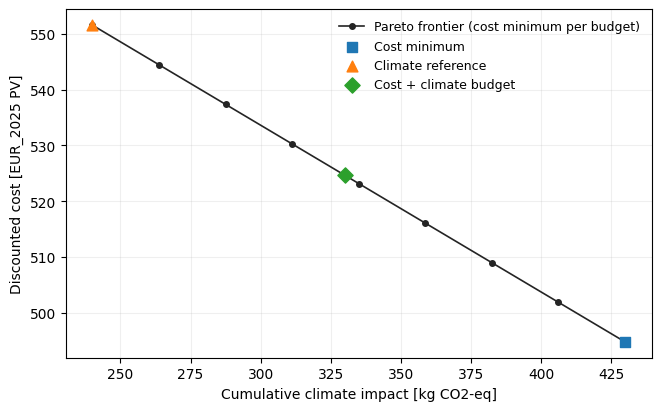

,Climate budget [kg CO2-eq],Climate [kg CO2-eq],Total cost [EUR_2025 PV],Abatement cost [EUR_2025/kg CO2-eq]
0,240.00,240.00,551.52,NaN
1,263.75,263.75,544.43,0.3
2,287.50,287.50,537.35,0.3
3,311.25,311.25,530.27,0.3
4,335.00,335.00,523.19,0.3
5,358.75,358.75,516.11,0.3
6,382.50,382.50,509.03,0.3
7,406.25,406.25,501.94,0.3
8,430.00,430.00,494.86,0.3


In [19]:
fig, ax = plt.subplots(figsize=(6.5, 4), layout="constrained")
ax.plot(frontier["Climate [kg CO2-eq]"], frontier["Total cost [EUR_2025 PV]"],
        color="#242424", marker="o", markersize=4, linewidth=1.2,
        label="Pareto frontier (cost minimum per budget)")
markers = {"Cost minimum": "s", "Climate reference": "^", "Cost + climate budget": "D"}
for scenario, marker in markers.items():
    ax.scatter(comparison.loc[scenario, "Climate [kg CO2-eq]"],
               comparison.loc[scenario, "Total cost [EUR_2025 PV]"],
               marker=marker, s=60, zorder=3, label=scenario)
ax.set(xlabel="Cumulative climate impact [kg CO2-eq]",
       ylabel="Discounted cost [EUR_2025 PV]")
ax.grid(alpha=0.2)
ax.legend(frameon=False, fontsize=9)
plt.show()

frontier.round(2)

In [20]:
# The frontier runs from the cost minimum to the climate minimum and never
# exceeds the cost of any reference pathway with the same or a lower impact.
assert np.isclose(frontier["Total cost [EUR_2025 PV]"].iloc[-1], minimum_cost)
assert np.isclose(frontier["Climate [kg CO2-eq]"].iloc[0], minimum_climate, atol=1e-4)
assert (frontier["Total cost [EUR_2025 PV]"].diff().dropna() <= 1e-6).all()
assert (
    frontier["Total cost [EUR_2025 PV]"].iloc[0]
    <= comparison.loc["Climate reference", "Total cost [EUR_2025 PV]"] + 1e-6
)

In this small system the frontier is a straight line: every kilogram of CO2-eq
avoided comes from the same substitution, shifting production from the
conventional to the advanced process, at a constant abatement cost of about
0.30 EUR_2025 per kg CO2-eq. The three scenarios from above lie on it. Systems
with more technologies typically give a kinked frontier, whose slope steepens
as the cheaper abatement options are used up.

Here the climate reference is also the cheapest pathway at the minimum climate
impact. That is not guaranteed in general: when several pathways reach the same
minimum impact, only the left end of the frontier is sure to be the cheapest.

## 10. Further reading

The essential chain is **Brightway exchanges + background prices -> processed
inputs -> objective and optional constraint -> results**.

- [Minimizing costs](../docs/content/minimizing_costs.md): pricing,
  discounting, and cost interpretation.
- [Foreground modeling](../docs/content/foreground_modeling.md) and
  [constraints](../docs/content/constraints.md): lifecycle timing, existing
  capacity, technology changes, and deployment limits.
- [Postprocessing](../docs/content/postprocessing.md): further result views.
- [Trade-offs](../docs/content/trade_offs.md) and
  [solving a series of models](../docs/content/solving.md#solving-a-series-of-models):
  sweeps, frontiers, and scenario comparisons with `optimizer.solve_series`.
- [Uncertainty example](uncertainty_example.ipynb): the same system with
  uncertain data and prices, analyzed with Monte Carlo sampling.
- [Basic example](basic_example.ipynb) and [methanol and iron](methanol_and_iron.ipynb):
  multi-product and connected foreground systems.

Those extensions are intentionally outside this introductory example.